<a href="https://colab.research.google.com/github/Ahm-445/PathWay-ab-test/blob/main/PathWay_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# المشروع الختامي: تصميم تجربة وتحليلها

**برنامج التجارب واختبارات A/B والاستدلال السببي**، العرض يوم الأربعاء 11 نوفمبر 2026

تعمل على المشروع **فرديًا أو ضمن فريق صغير** حسب ما يحدده المدرب.

| القسم | موعد كتابته |
|---|---|
| 0. بيانات المشروع، 1. السؤال والفرضية، 2. التصميم | الأحد، الجلسة الرابعة |
| 3. حجم العينة والمدة | الإثنين، الجلسة الرابعة |
| 4. خطة التحليل، 5. إنشاء البيانات، 6. فحوص الثقة، 7. التحليل | الثلاثاء، الجلسة الرابعة |
| 8. (اختياري) بديل شبه تجريبي | الثلاثاء، الجلسة الرابعة |
| 9. التقرير والتوصية | الأربعاء، الجلسة الثانية |
| رابط المستودع على GitHub | https://github.com/Ahm-445/PathWay-ab-test |

**المطلوب تسليمه آخر اليوم الرابع:** مستودع عام على GitHub فيه هذا الدفتر مكتملًا وملف README، وتقرير من صفحة واحدة (القسم 9)، وعرض مدته 10 دقائق. خطوات الحفظ في GitHub وقالب README في القسم 10.

> البيانات هنا من **محاكاة**: أنت تحدد الأثر الحقيقي بنفسك، ثم ترى هل يصل تحليلك إليه. في الواقع لا نعرف الأثر الحقيقي، ولهذا نتدرب على المحاكاة أولًا.

</div>

<div dir="rtl">

## 0. بيانات المشروع

</div>

<div dir="rtl">


| البند | القيمة |
|---|---|
| عنوان المشروع | تذكير السلة المتروكة: هل يرفع إتمام الشراء؟ |
| الاسم / أعضاء الفريق | أحمد القحطاني، محمد البديع، زياد الحميد، محمد ال عتيق |
| نوع العمل | فريق |
| المجموعة | PathWay |
| المنتج | متجر إلكتروني (تطبيق وموقع) |
| القرار المطلوب | نطلق رسالة تذكير السلة المتروكة لكل المستخدمين أو لا نطلقها |
| اسم التجربة (للتوزيع) | `cart_reminder_v1` |
| تاريخ البدء | 8 نوفمبر 2026 |
| رابط المستودع على GitHub | *(يُضاف يوم الأربعاء)* |

</div>

<div dir="rtl">

## 1. السؤال والفرضية

</div>

<div dir="rtl">


**السؤال:** هل يرفع إرسال تذكير بالسلة المتروكة (إشعار في التطبيق أو بريد) بعد 3 ساعات من ترك السلة نسبةَ المستخدمين الذين يُتمّون الشراء خلال 7 أيام؟

**القرار المرتبط بالسؤال:** إذا ثبت أثر إيجابي يستحق التكلفة، ولم تسُؤ مقاييس الحماية، نطلق التذكير لكل المستخدمين. وإلا لا نطلقه.

**الفرضية:** إذا أرسلنا تذكيرًا للمستخدم بعد 3 ساعات من ترك سلته فستزيد نسبة إتمام الشراء، **لأن** جزءًا من ترك السلة سببه النسيان أو الانشغال وليس عدم الرغبة في المنتج، والتذكير يعيد المستخدم إلى السلة في وقت مناسب.

**الصيغة الإحصائية:**
- الفرضية الصفرية H₀: نسبة إتمام الشراء في B = نسبتها في A (الأثر = 0)
- الفرضية البديلة H₁: النسبتان مختلفتان (اختبار ثنائي الطرف، α = 5%)

**الأثر المستهدف (مبدئيًا):** النسبة الأساسية المتوقعة لإتمام الشراء بعد ترك السلة حوالي 8%، وأصغر أثر يهمنا عمليًا **نقطة مئوية واحدة** (من 8% إلى 9%). نحسب حجم العينة والمدة في اليوم الثاني.

**ماذا كان سيحدث بدون المعالجة؟** تمثله المجموعة A: نفس المستخدمين المؤهلين بلا تذكير، ويحدد التوزيع بالقرعة من يذهب إلى كل مجموعة.
</div>

<div dir="rtl">

## 2. التصميم

</div>

<div dir="rtl">


### المجموعتان
| | A (الضابطة) | B (المعالجة) |
|---|---|---|
| ما يحدث | لا تذكير (الوضع الحالي) | تذكير واحد بعد 3 ساعات من ترك السلة: إشعار في التطبيق، أو بريد لمن أوقف الإشعارات |
| نسبة التوزيع | 50% | 50% |

### الفئة المؤهلة ونقطة الدخول في التجربة
- مستخدم مسجّل أضاف منتجًا واحدًا على الأقل إلى السلة، ثم مرت **ساعة** دون شراء.
- يدخل المستخدم التجربة **مرة واحدة** عند أول سلة متروكة خلال فترة التجربة، ويُقاس من تلك اللحظة.
- نستبعد مسبقًا (قبل التوزيع وفي المجموعتين معًا): حسابات الموظفين والاختبار، ومن ألغى الاشتراك في كل وسائل التواصل.

### وحدة العشوأة
**المستخدم (`user_id`)**. السبب: التذكير ميزة يراها المستخدم نفسه، ويجب أن يرى النسخة نفسها في كل زياراته وعلى كل أجهزته. لا نستخدم الجلسة لأن المستخدم قد يرى نسختين، ولا نحتاج إلى مجموعة (مدينة) لأن المستخدمين لا يؤثر بعضهم في بعض في هذا السياق.

**شرط SUTVA:** متحقق في الغالب، فتذكير مستخدم لا يغيّر شراء مستخدم آخر. خطر بسيط: الحسابات العائلية المشتركة، وأثره صغير.

### التوزيع الثابت
`hash(user_id + "cart_reminder_v1") % 100`: أقل من 50 يعني A، وغير ذلك B. المستخدم نفسه يبقى في النسخة نفسها دائمًا، والتوزيع مستقل عن أي تجربة أخرى.

### المقاييس
| النوع | المقياس | التعريف |
|---|---|---|
| **رئيسي (واحد فقط)** | نسبة إتمام الشراء | نسبة المستخدمين المؤهلين الذين أتموا طلبًا واحدًا على الأقل خلال 7 أيام من دخولهم التجربة |
| حماية | إلغاء الاشتراك في الإشعارات أو البريد | نسبة المستخدمين الذين أوقفوا الإشعارات أو ألغوا البريد خلال 7 أيام |
| حماية | حذف التطبيق | نسبة من حذفوا التطبيق خلال 7 أيام |
| حماية | نسبة الاسترجاع | نسبة الطلبات المسترجعة من طلبات الفترة |
| ثانوي | متوسط قيمة السلة | متوسط قيمة الطلب للمشترين |
| ثانوي | الإيراد لكل مستخدم | إجمالي الإيراد ÷ عدد المستخدمين في المجموعة (نسبة مقياسين: نحلله بطريقة دلتا) |
| ثانوي | الوقت حتى الشراء | الساعات من ترك السلة حتى الطلب |

### فحوص الثقة قبل التحليل
- **اختبار A/A** على نظام التوزيع قبل البدء: نتوقع حوالي 5% فقط من المقارنات «دالة».
- **فحص نسبة التوزيع (SRM)** بكاي تربيع على أعداد A وB، ونوقف التحليل إذا كانت p < 0.001.
- التأكد من أن التذكير أُرسل فعلًا في B ولم يُرسل في A.

### المدة
نحسبها في اليوم الثاني من حجم العينة وعدد المستخدمين المؤهلين يوميًا، ونقرّبها إلى **أسابيع كاملة**.

### قاعدة القرار (مبدئية، قبل رؤية أي نتيجة)
- **نطلق** إذا كان الحد الأدنى لفترة الثقة 95% للمقياس الرئيسي أكبر من صفر، ولم يسؤ أي مقياس حماية بشكل دال.
- **لا نطلق الآن** إذا تحسن المقياس الرئيسي وساء مقياس حماية: نعالج المشكلة (مثلًا نخفف عدد التذكيرات) ثم نعيد التحقق.
- **لا نطلق** إذا شملت فترة الثقة الصفر ولم تشمل أثرًا بحجم نقطة واحدة.

</div>

In [1]:
# القسم 2 (تابع): التوزيع الثابت بالـ hash، والتحقق منه، وفحص SRM
import hashlib
import numpy as np
from scipy import stats

EXPERIMENT = "cart_reminder_v1"

def bucket(user_id, experiment=EXPERIMENT):
    """رقم ثابت من 0 إلى 99 لكل مستخدم داخل هذه التجربة."""
    h = hashlib.md5(f"{user_id}{experiment}".encode()).hexdigest()
    return int(h, 16) % 100

def assign(user_id, pct_b=50, experiment=EXPERIMENT):
    return "B" if bucket(user_id, experiment) >= 100 - pct_b else "A"

# 1) المستخدم نفسه يرى النسخة نفسها في كل مرة
print("user_123 خمس مرات:", [assign("user_123") for _ in range(5)])

# 2) النسبة الفعلية قريبة من 50%
users = [f"user_{i}" for i in range(100_000)]
groups = np.array([assign(u) for u in users])
n_a, n_b = (groups == "A").sum(), (groups == "B").sum()
print(f"A = {n_a:,}   B = {n_b:,}   نسبة B = {n_b / len(users):.3f}")

# 3) فحص SRM: بكاي تربيع مقابل التصميم 50/50
def srm_check(n_a, n_b, expected_b=0.5, threshold=0.001):
    total = n_a + n_b
    chi2, p = stats.chisquare([n_a, n_b], [total * (1 - expected_b), total * expected_b])
    verdict = "خلل في التوزيع: أوقف التحليل" if p < threshold else "سليم"
    print(f"SRM: chi2 = {chi2:.2f}, p = {p:.4f} -> {verdict}")
    return p

_ = srm_check(n_a, n_b)


user_123 خمس مرات: ['B', 'B', 'B', 'B', 'B']
A = 49,693   B = 50,307   نسبة B = 0.503
SRM: chi2 = 3.77, p = 0.0522 -> سليم


<div dir="rtl">

## أدوات جاهزة

شغّل الخلية التالية بدون تعديل. فيها كل الدوال التي استخدمناها في الأيام الأربعة.

</div>

In [2]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import Markdown, display


def n_per_group_proportions(p_control, p_treatment, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    var = p_control * (1 - p_control) + p_treatment * (1 - p_treatment)
    return int(np.ceil((z_a + z_b) ** 2 * var / (p_treatment - p_control) ** 2))


def mde_proportions(p_control, n_per_group, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 * p_control * (1 - p_control) / n_per_group)


def duration_days(n_per_group, daily_new_users, groups=2, round_to_weeks=True):
    days = int(np.ceil(n_per_group * groups / daily_new_users))
    return int(np.ceil(days / 7) * 7) if round_to_weeks else days


def srm_check(n_a, n_b, expected_share_b=0.5, threshold=0.001):
    total = n_a + n_b
    chi2, p = stats.chisquare([n_a, n_b], f_exp=[total * (1 - expected_share_b), total * expected_share_b])
    verdict = "خلل في التوزيع (SRM)، لا تثق بالنتائج" if p < threshold else "التوزيع سليم"
    say(f"A={n_a:,}   B={n_b:,}   χ²={chi2:.2f}   p={p:.2g}   النتيجة: {verdict}")
    return p


def diff_ci(a, b, alpha=0.05):
    """الفرق بين B وA مع فترة الثقة وقيمة p (بالتقريب الطبيعي)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    z = stats.norm.ppf(1 - alpha / 2)
    return {"الفرق": diff, "أدنى 95%": diff - z * se, "أعلى 95%": diff + z * se, "SE": se,
            "p": 2 * stats.norm.sf(abs(diff / se))}


def decide(ci_low, ci_high, mde, guardrails_ok=True):
    if ci_high < 0:
        return "لا نطلق، لأن النسخة الجديدة أضرت بالمقياس الرئيسي."
    if ci_low > 0 and not guardrails_ok:
        return "لا نطلق الآن، لأن المقياس الرئيسي تحسن لكن أحد مقاييس الحماية ساء. نعالج المشكلة ثم نعيد التحقق."
    if ci_low > 0:
        return "نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة."
    if ci_high < mde:
        return "لا نطلق، لأننا استبعدنا وجود أثر بالحجم الذي يهمنا."
    return "لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى."


say("الأدوات جاهزة")

<div dir="rtl">

# القسم 3: حجم العينة والمدة

**المدخلات:**
- النسبة الأساسية لإتمام الشراء بعد ترك السلة: **8%**
- أصغر أثر يهمنا: **نقطة مئوية واحدة** (من 8% إلى 9%)
- القوة 80%، ومستوى الدلالة 5% (ثنائي الطرف)
- عدد المستخدمين المؤهلين الجدد (أول سلة متروكة) في اليوم: **2,500** تقريبًا

نحسب حجم العينة بالمعادلة، ثم نتحقق منه بالمحاكاة، ثم نحوله إلى مدة بأسابيع كاملة.

</div>

In [3]:
CONFIG = {
    "project": "تذكير السلة المتروكة",       # عدّل
    # ---- التصميم (تعرفه قبل التجربة) ----
    "baseline_conversion": 0.08,   # عدّل: القيمة الحالية للمقياس الرئيسي
    "mde_abs": 0.010,              # عدّل: أصغر أثر يغير القرار
    "alpha": 0.05,
    "power": 0.80,
    "daily_new_users": 2_500,      # عدّل: عدد المستخدمين الجدد في اليوم
    "treatment_share": 0.5,
    # ---- المحاكاة ("الحقيقة" المخفية): عدّلها بما يناسب مشروعك ----
    "true_lift_abs": 0.012,
    "order_value_mean": 190,
    "order_value_sd": 80,
    "order_value_effect": 0,
    "margin": 0.25,
    "extra_cost_per_order_b": 0,
    "cancel_rate": 0.05, "cancel_effect": 0.000,
    "support_rate": 0.03, "support_effect": 0.004,
    "activity_strength": 0.8,
    "novelty_boost": 0.3,
    "srm_bug_share": 0.0,
    "seed": 2026,
}

In [6]:
c = CONFIG
n_per_group = n_per_group_proportions(c["baseline_conversion"], c["baseline_conversion"] + c["mde_abs"], c["alpha"], c["power"])
days = duration_days(n_per_group, c["daily_new_users"])
say(f"المشروع: {c['project']}")
say(f"حجم العينة: {n_per_group:,} في كل مجموعة، أي {2 * n_per_group:,} مستخدم في المجموع")
say(f"المدة: {days} يومًا، وعدد الأسابيع الكاملة: {days // 7}")
n_planned = days * c["daily_new_users"] // 2
say(f"عدد المستخدمين المتوقع خلال المدة: {n_planned:,} في كل مجموعة")
for label, n_g in [("في المدة المخططة", n_planned), ("إذا اكتفينا بأسبوع واحد", 7 * c["daily_new_users"] // 2)]:
    m = mde_proportions(c["baseline_conversion"], n_g, c["alpha"], c["power"])
    say(f"{label}: أصغر أثر قابل للاكتشاف حوالي {m * 100:.2f} نقطة")

<div dir="rtl">

**قرارك في حجم العينة والمدة:** هل المدة مقبولة؟ وإذا لم تكن مقبولة، فماذا ستغير؟

</div>

<div dir="rtl">

<div dir="rtl">

**المدة مقبولة.** نحتاج 12,206 مستخدمين في كل مجموعة (24,412 في المجموع). بمعدل 2,500 مستخدم مؤهل في اليوم يكفي ذلك نحو 10 أيام، فقربناها إلى **14 يومًا (أسبوعان كاملان)** حتى يظهر كل يوم من أيام الأسبوع بالعدد نفسه.

- خلال 14 يومًا سيدخل التجربة حوالي 17,500 مستخدم في كل مجموعة، وأصغر أثر نستطيع اكتشافه **0.81 نقطة**، وهو أقل من النقطة الواحدة التي تهمنا.
- إذا اكتفينا بأسبوع واحد فأصغر أثر قابل للاكتشاف 1.15 نقطة، وهو أكبر مما يهمنا، فلن نوقف التجربة قبل أسبوعين.
- لا نحتاج إلى تغيير التصميم. ولو كان عدد المستخدمين أقل من المتوقع فسنمدد المدة إلى 3 أسابيع، ولن نرفع أصغر أثر يهمنا.

</div>

</div>

<div dir="rtl">

## 4. خطة التحليل

اكتبها **قبل** تشغيل القسم 5. وأي تغيير تجريه بعد رؤية النتائج يجب أن تذكره في التقرير.

</div>

<div dir="rtl">

1. **فحص نسبة التوزيع (SRM):** اختبار بكاي تربيع على أعداد A وB مقابل التصميم 50/50. إذا كانت p أقل من 0.001 نتوقف ولا نحلل حتى نجد سبب الخلل.
2. **المقياس الرئيسي:** نسبة المستخدمين الذين طلبوا (`ordered`). نقدر الفرق B − A مع فترة ثقة 95%، ثم نعيده مع **CUPED** باستخدام الطلبات في آخر 90 يومًا قبل التجربة (`pre_orders_90d`). نحلل **كل** من وُزع بالقرعة، ولا نفلتر على شيء يحدث بعد المعالجة مثل «من فتح التذكير».
3. **مقاييس ثانوية:** قيمة الطلب لمن طلب، والإيراد لكل مستخدم. نصحح قيم p بطريقة **Benjamini-Hochberg** لأنها أكثر من مقياس.
4. **مقاييس الحماية:** الربح لكل مستخدم (السيئ أن ينخفض)، ونسبة إلغاء الطلبات، والتواصل مع الدعم (السيئ أن يرتفعا). التواصل مع الدعم في المحاكاة يمثل الإزعاج والشكاوى من التذكيرات. ويكون مقياس الحماية «متدهورًا» إذا كانت فترة الثقة كلها في الاتجاه السيئ.
5. **متى نحلل:** مرة واحدة بعد انتهاء 14 يومًا كاملة. لا نطلع على النتيجة قبل ذلك، ولا نوقف التجربة عند أول نتيجة دالة. ونرسم الأثر لكل يوم دخول لنفحص أثر الحداثة.
6. **قاعدة القرار:** نطلق إذا كان الحد الأدنى لفترة الثقة أكبر من صفر وكل مقاييس الحماية سليمة. وإذا تحسن المقياس الرئيسي وساء مقياس حماية: لا نطلق الآن، ونعالج المشكلة ثم نعيد التحقق. وإذا كان الحد الأعلى أقل من نقطة واحدة: لا نطلق. وإذا شملت الفترة الصفر والنقطة الواحدة معًا: لا نقرر بعد ونمدد التجربة.

</div>

<div dir="rtl">

## 5. إنشاء البيانات بالمحاكاة

تنشئ المحاكاة كل المستخدمين الذين يدخلون التجربة خلال المدة، وكل مستخدم في صف واحد. لكل مستخدم: النسخة، ويوم الدخول، وطلباته في آخر 90 يومًا قبل التجربة، وهل طلب، وقيمة الطلب، والربح، والإلغاء، والتواصل مع الدعم.

</div>

In [7]:
def simulate_experiment(cfg, duration_days):
    """كل المستخدمين الذين يدخلون خلال مدة التجربة (المدة مضروبة في عدد المستخدمين اليومي)."""
    r = np.random.default_rng(cfg["seed"])
    n = duration_days * cfg["daily_new_users"]
    is_b = (r.random(n) < cfg["treatment_share"]).astype(int)
    day = r.integers(1, duration_days + 1, n)
    activity = r.normal(0, 1, n)                                             # نشاط المستخدم (لا نقيسه مباشرة)
    base = cfg["baseline_conversion"]
    logit = np.log(base / (1 - base)) + cfg["activity_strength"] * activity
    p0 = 1 / (1 + np.exp(-logit))
    p0 = np.clip(p0 * base / p0.mean(), 0, 1)                                # نضبط المتوسط ليساوي خط الأساس
    pre_orders_90d = r.poisson(5 * p0 / base)                                # الطلبات في آخر 90 يومًا
    lift = cfg["true_lift_abs"] * (1 + cfg["novelty_boost"] * np.exp(-(day - 1) / 3))
    ordered = r.binomial(1, np.clip(p0 + lift * is_b, 0, 1))
    value = np.maximum(10, r.normal(cfg["order_value_mean"] + cfg["order_value_effect"] * is_b, cfg["order_value_sd"]))
    order_value = np.where(ordered == 1, value, np.nan)
    revenue = ordered * value
    profit = ordered * (cfg["margin"] * value - cfg["extra_cost_per_order_b"] * is_b)
    cancelled = np.where(ordered == 1, r.binomial(1, np.clip(cfg["cancel_rate"] + cfg["cancel_effect"] * is_b, 0, 1)), np.nan)
    support = r.binomial(1, np.clip(cfg["support_rate"] + cfg["support_effect"] * is_b, 0, 1))
    df = pd.DataFrame({"variant": np.where(is_b == 1, "B", "A"), "day": day, "pre_orders_90d": pre_orders_90d,
                       "ordered": ordered, "order_value": order_value, "revenue": revenue, "profit": profit,
                       "cancelled": cancelled, "contacted_support": support})
    if cfg["srm_bug_share"] > 0:                                              # خلل: سجلات ضائعة من B لقليلي النشاط
        lost = (df["variant"] == "B") & (activity < 0) & (r.random(n) < cfg["srm_bug_share"] * 2)
        df = df[~lost]
    return df.reset_index(drop=True)


data = simulate_experiment(CONFIG, days)
say(f"عدد المستخدمين: {len(data):,}")
data.head()

,variant,day,pre_orders_90d,ordered,order_value,revenue,profit,cancelled,contacted_support
0,B,1,2,0,NaN,0.0000,0.0000,NaN,0
1,A,5,2,0,NaN,0.0000,0.0000,NaN,0
2,B,10,7,0,NaN,0.0000,0.0000,NaN,0
3,B,9,8,0,NaN,0.0000,0.0000,NaN,0
4,B,4,4,1,237.3624,237.3624,59.3406,0.0,0


<div dir="rtl">

## 6. فحوص الثقة

</div>

In [8]:
counts = data["variant"].value_counts()
srm_check(counts.get("A", 0), counts.get("B", 0), CONFIG["treatment_share"]);

<div dir="rtl">

## 7. التحليل

### 7.1 المقياس الرئيسي، مع CUPED

</div>

In [9]:
A, B = data[data.variant == "A"], data[data.variant == "B"]
primary = diff_ci(A["ordered"], B["ordered"])

theta = np.cov(data["ordered"], data["pre_orders_90d"])[0, 1] / data["pre_orders_90d"].var(ddof=1)
adjusted = data["ordered"] - theta * (data["pre_orders_90d"] - data["pre_orders_90d"].mean())
primary_cuped = diff_ci(adjusted[data.variant == "A"], adjusted[data.variant == "B"])

out = pd.DataFrame([primary, primary_cuped], index=["بدون تعديل", "مع CUPED"])
out[["الفرق", "أدنى 95%", "أعلى 95%"]] *= 100
say(f"نسبة الطلب في A: {A['ordered'].mean():.2%}، وفي B: {B['ordered'].mean():.2%}")
say(f"انخفاض التباين بطريقة CUPED: {1 - (primary_cuped['SE'] / primary['SE']) ** 2:.0%}")
out.round(3)

,الفرق,أدنى 95%,أعلى 95%,SE,p
بدون تعديل,1.213,0.621,1.806,0.003,0.0
مع CUPED,1.219,0.637,1.801,0.003,0.0


<div dir="rtl">

تقلل طريقة CUPED التباين بوضوح أكبر في المقاييس المتصلة مثل الإيراد. أما في المقاييس التي قيمتها نعم أو لا، مثل "هل طلب؟"، فيكون التقليل أصغر عادة.

</div>

<div dir="rtl">

### 7.2 المقاييس الثانوية، مع تصحيح الاختبارات المتعددة

</div>

In [10]:
secondary = {
    "قيمة الطلب (لمن طلب)": diff_ci(A["order_value"].dropna(), B["order_value"].dropna()),
    "الإيراد لكل مستخدم": diff_ci(A["revenue"], B["revenue"]),
}
sec = pd.DataFrame(secondary).T
sec["دال بعد تصحيح BH"] = multipletests(sec["p"].astype(float), alpha=0.05, method="fdr_bh")[0]
sec.round(3)

,الفرق,أدنى 95%,أعلى 95%,SE,p,دال بعد تصحيح BH
قيمة الطلب (لمن طلب),-4.651,-10.177,0.876,2.820,0.099,False
الإيراد لكل مستخدم,1.926,0.688,3.164,0.632,0.002,True


<div dir="rtl">

### 7.3 مقاييس الحماية

</div>

In [11]:
guardrail_defs = {                       # العمود: (الاسم، والاتجاه السيئ)
    "profit": ("الربح لكل مستخدم", "down"),
    "cancelled": ("نسبة إلغاء الطلبات", "up"),
    "contacted_support": ("التواصل مع الدعم", "up"),
}
rows, guard_status = [], {}
for col, (label, bad) in guardrail_defs.items():
    res = diff_ci(A[col].dropna(), B[col].dropna())
    harmful = res["أعلى 95%"] < 0 if bad == "down" else res["أدنى 95%"] > 0
    status = "تدهور دال" if harmful else "سليم"
    guard_status[label] = status
    rows.append({"المقياس": label, "A": A[col].mean(), "B": B[col].mean(), **res, "الحالة": status})
guard_table = pd.DataFrame(rows).set_index("المقياس")
guard_table.round(4)

,A,B,الفرق,أدنى 95%,أعلى 95%,SE,p,الحالة
المقياس,,,,,,,,
الربح لكل مستخدم,3.9734,4.4549,0.4815,0.1720,0.7909,0.1579,0.0023,سليم
نسبة إلغاء الطلبات,0.0549,0.0412,-0.0137,-0.0289,0.0016,0.0078,0.0786,سليم
التواصل مع الدعم,0.0302,0.0372,0.0070,0.0032,0.0108,0.0019,0.0003,تدهور دال


<div dir="rtl">

### 7.4 فحص أثر الحداثة

</div>

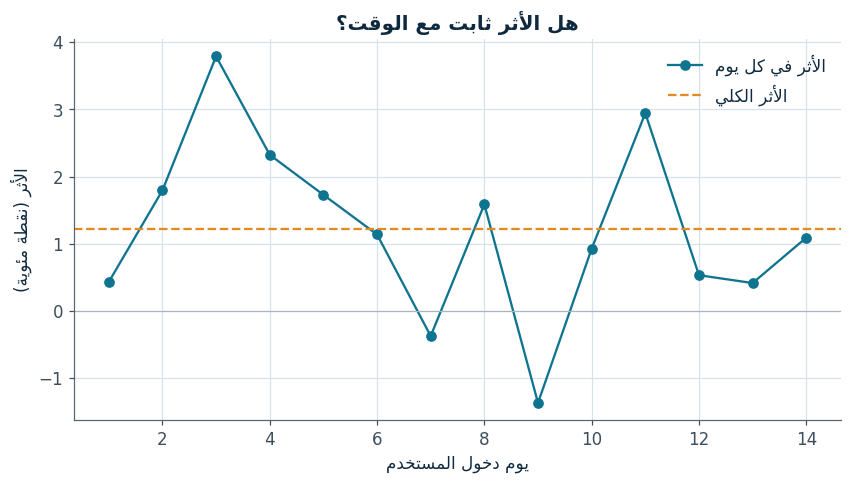

In [12]:
daily = data.groupby(["day", "variant"])["ordered"].mean().unstack()
daily_lift = (daily["B"] - daily["A"]) * 100
plt.plot(daily_lift.index, daily_lift.values, marker="o", color=TEAL, label=ar("الأثر في كل يوم"))
plt.axhline(primary["الفرق"] * 100, color=ORANGE, linestyle="--", label=ar("الأثر الكلي"))
plt.axhline(0, color=GRAY, linewidth=0.8)
plt.xlabel(ar("يوم دخول المستخدم"))
plt.ylabel(ar("الأثر (نقطة مئوية)"))
plt.title(ar("هل الأثر ثابت مع الوقت؟"))
plt.legend()
plt.show()

<div dir="rtl">

## 8. (اختياري) إذا لم تستطع إجراء تجربة: الفروق في الفروق

إذا كان مشروعك سياسة طُبقت في مناطق دون غيرها، فعدّل الإعدادات في الخلية التالية، وطبق خطوات اليوم الثالث نفسها.

</div>

In [13]:
def simulate_policy_panel(n_units=20, n_treated=6, n_periods=24, policy_period=13, effect=8.0, seed=32):
    r = np.random.default_rng(seed)
    level = r.normal(100, 15, n_units)
    shock = r.normal(0, 2, n_periods)
    rows = []
    for i in range(n_units):
        for t in range(1, n_periods + 1):
            treated, post = int(i < n_treated), int(t >= policy_period)
            y = level[i] + 0.8 * t + shock[t - 1] + effect * treated * post + r.normal(0, 3)
            rows.append({"unit": i, "period": t, "treated": treated, "post": post, "y": y})
    df = pd.DataFrame(rows)
    df["treated_post"] = df["treated"] * df["post"]
    return df


policy = simulate_policy_panel()
twfe = smf.ols("y ~ treated_post + C(unit) + C(period)", data=policy).fit(
    cov_type="cluster", cov_kwds={"groups": policy["unit"]})
lo, hi = twfe.conf_int().loc["treated_post"]
say(f"أثر السياسة: {twfe.params['treated_post']:.2f}، وفترة الثقة 95% من {lo:.2f} إلى {hi:.2f}")

<div dir="rtl">

## 9. التقرير والتوصية

الخلية التالية تنشئ تقرير الصفحة الواحدة من نتائج القسم 7. عدّل عدد المستخدمين السنوي حسب مشروعك.

</div>

In [14]:
annual_users = 912_500                   # عدّل: عدد المستخدمين في السنة الذين يتأثرون بالقرار
guardrails_ok = all(s == "سليم" for s in guard_status.values())
decision = decide(primary["أدنى 95%"], primary["أعلى 95%"], CONFIG["mde_abs"], guardrails_ok)
profit = guard_table.loc["الربح لكل مستخدم"]
guard_rows = "\n".join(f"| {k} | {v} |" for k, v in guard_status.items())

report = f"""
<div dir="rtl">

### تقرير التجربة: {CONFIG['project']}

**القرار:** {decision}

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من {A['ordered'].mean():.2%} إلى {B['ordered'].mean():.2%} |
| الأثر | {primary['الفرق'] * 100:.2f} نقطة (فترة الثقة 95%: من {primary['أدنى 95%'] * 100:.2f} إلى {primary['أعلى 95%'] * 100:.2f}) |
| الأثر مع CUPED | {primary_cuped['الفرق'] * 100:.2f} نقطة (من {primary_cuped['أدنى 95%'] * 100:.2f} إلى {primary_cuped['أعلى 95%'] * 100:.2f}) |
| التغير التقديري في الربح السنوي | {profit['الفرق'] * annual_users / 1e6:.2f} مليون ريال (من {profit['أدنى 95%'] * annual_users / 1e6:.2f} إلى {profit['أعلى 95%'] * annual_users / 1e6:.2f}) |

| مقياس الحماية | الحالة |
|---|---|
{guard_rows}

</div>
"""
display(Markdown(report))


<div dir="rtl">

### تقرير التجربة: تذكير السلة المتروكة

**القرار:** لا نطلق الآن، لأن المقياس الرئيسي تحسن لكن أحد مقاييس الحماية ساء. نعالج المشكلة ثم نعيد التحقق.

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من 8.16% إلى 9.38% |
| الأثر | 1.21 نقطة (فترة الثقة 95%: من 0.62 إلى 1.81) |
| الأثر مع CUPED | 1.22 نقطة (من 0.64 إلى 1.80) |
| التغير التقديري في الربح السنوي | 0.44 مليون ريال (من 0.16 إلى 0.72) |

| مقياس الحماية | الحالة |
|---|---|
| الربح لكل مستخدم | سليم |
| نسبة إلغاء الطلبات | سليم |
| التواصل مع الدعم | تدهور دال |

</div>


<div dir="rtl">

**توصيتك النهائية والقيود** (من 3 إلى 5 أسطر):

</div>

<div dir="rtl">

- **التوصية:** **لا نطلق الآن.** رفع التذكير نسبة الطلب من 8.16% إلى 9.38%، أي **+1.22 نقطة مع CUPED (فترة الثقة 95% من 0.64 إلى 1.80)**، والربح لكل مستخدم زاد (حوالي 0.44 مليون ريال في السنة، من 0.16 إلى 0.72). لكن التواصل مع الدعم ارتفع من 3.02% إلى 3.72%، أي **+0.70 نقطة (من 0.32 إلى 1.08)**، وهذا تدهور دال في مقياس حماية، أي حوالي 6,400 تواصل إضافي في السنة.
- **الخطوة التالية:** نراجع أسباب التواصل مع الدعم في النسخة B، ونجرب تذكيرًا بصياغة أوضح فيها رابط مباشر للسلة وخيار لإيقاف التذكيرات، ثم نعيد التجربة بالمقياس الرئيسي نفسه.
- **القيود:** البيانات **محاكاة** وليست بيانات متجر حقيقي. والأثر في الأيام الأولى أعلى من الأيام الأخيرة، وقد يكون جزء منه **أثر حداثة**، فالأثر بعد أن يستقر قد يكون أقل من 1.22. ونافذة القياس أسبوعان فقط، ولم نقس إلغاء الاشتراك في الإشعارات الذي ذكرناه في التصميم لأن المحاكاة لا تتضمنه. وقلل CUPED التباين 3% فقط لأن المقياس قيمته نعم أو لا.

</div>

<div dir="rtl">

## 10. التسليم على GitHub

يُسلَّم المشروع آخر اليوم الرابع مستودعًا على GitHub، ويُقيَّم منه. تعمل طوال الأيام الأربعة في نسختك على Drive، ثم تحفظ الدفتر في المستودع يوم الأربعاء.

**قبل يوم الأربعاء**

1. أنشئ حسابًا على [github.com](https://github.com) إن لم يكن لديك.
2. أنشئ مستودعًا جديدًا: من زر **New repository** اكتب اسمًا واضحًا مثل `free-delivery-ab-test`، واختر **Public**، وفعّل **Add a README file**، ثم **Create repository**.
3. في العمل الجماعي ينشئ عضو واحد المستودع، ويضيف زملاءه من **Settings** ثم **Collaborators**.

**آخر يوم الأربعاء، للتسليم**

1. في Colab اختر **File** ثم **Save a copy in GitHub**. في المرة الأولى وافق على ربط حسابك.
2. اختر مستودعك، واكتب في **Commit message** وصفًا قصيرًا، مثل: `النسخة النهائية من المشروع`، ثم اضغط **OK**.
3. افتح ملف `README.md` في المستودع، واضغط رمز القلم، والصق القالب الذي تحت هذه الخطوات، وأكمله.
4. ضع رابط المستودع، بالشكل `https://github.com/اسم-الحساب/اسم-المستودع`، في ملف التقييم.

**قالب README**

```markdown
# اسم المشروع

## الوصف
جملتان: ما المنتج أو الخدمة، وما القرار الذي تساعد التجربة على اتخاذه.

## السؤال والفرضية
- القرار:
- الفرضية:

## التصميم
- وحدة العشوأة:
- المقياس الرئيسي ومقاييس الحماية:
- حجم العينة والمدة:

## النتائج والتوصية
- الأثر الرئيسي وفترة الثقة:
- التوصية:

## طريقة التشغيل
1. افتح الدفتر في Google Colab: من GitHub افتح الملف ثم Open in Colab، أو من Colab اختر File ثم Open notebook ثم GitHub.
2. شغّل الخلايا بالترتيب. البيانات من محاكاة ببذرة ثابتة، فتتكرر النتائج نفسها.

## المتطلبات
Python 3 ومكتبات numpy وpandas وscipy وstatsmodels وmatplotlib، وكلها موجودة في Colab.

## التوثيق الفني
- القسم 3: حجم العينة والمدة.
- القسم 6: فحوص الثقة ونسبة التوزيع.
- القسم 7: التحليل مع CUPED وتصحيح الاختبارات المتعددة.
- القسم 9: التقرير والتوصية.

## هيكل المستودع
- project_template.ipynb: دفتر المشروع
- README.md: هذا الملف

## عن البرنامج
نُفّذ هذا المشروع ضمن برنامج «التجارب واختبارات A/B والاستدلال السببي» في أكاديمية سدايا، نوفمبر 2026.
حساب أكاديمية سدايا على GitHub: https://github.com/SDAIAAcademy
```

</div>

<div dir="rtl">

## قائمة التسليم

- المستودع عام على GitHub، وفيه الدفتر وملف README مكتملًا.
- رابط المستودع في ملف التقييم.
- الأقسام من 0 إلى 4 مكتوبة، وخطة التحليل مكتوبة قبل إنشاء البيانات.
- فحص نسبة التوزيع سليم، أو سبب الخلل موضح.
- الأثر الرئيسي معه فترة ثقة، والمقاييس الثانوية مصححة.
- حالة كل مقياس من مقاييس الحماية واضحة.
- تقرير الصفحة الواحدة جاهز، والتوصية موجودة في أول شريحة وآخر شريحة من العرض.

</div>